# 04 · Template extras: B5 heat-map sanity check, C3 calibration, exact versions

The course template (`BIA_W6_Project_Template.ipynb`) also asks for **B5** (do the heat maps
depend on what the network learned?), **C3** (are the probabilities honest?) and a
`requirements.txt` with exact versions (C5). This notebook adds them **without training again**:
it loads the 6 U-Nets that notebook 03 saved to Google Drive (`MyDrive/kvasir_seg_runs`).

**Colab: Runtime → Run all.** No GPU needed (about 3 minutes). Allow Google Drive when asked.

In [2]:
import os, sys, json, copy
# On Colab: download our code from GitHub first (on a laptop it is already there).
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
# If started inside chandana/ or dinesh/, go up to the project folder, so data/ and src/ are found.
if os.path.basename(os.getcwd()) in ("chandana", "dinesh"):
    os.chdir("..")
# Data not there yet: download Kvasir-SEG (46 MB) and the authors' split lists.
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py
# Split not made yet: fingerprints, duplicate check, train/val/test lists.
if not os.path.exists("splits/train.txt"):
    !python scripts/make_split.py
# Let Python import our own modules from src/.
sys.path.insert(0, "src")

import numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from pathlib import Path
from data import load_resized, read_split
from metrics import mean_scores
from unet import UNet
from train import predict_probs, to_tensor, normalise

if "google.colab" in sys.modules:
    from google.colab import drive
    # Google Drive keeps the trained models between Colab sessions.
    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/kvasir_seg_runs")
else:
    RUNS = Path("checkpoints")
# Use the GPU if there is one (Colab T4), otherwise the CPU.
device = "cuda" if torch.cuda.is_available() else "cpu"
# Every table and figure is saved in results/.
R = Path("results"); R.mkdir(exist_ok=True)

names = read_split("test")
pairs = [load_resized(n, 256) for n in names]
X = np.stack([p[0] for p in pairs]); Y = np.stack([p[1] for p in pairs])

# Load the 6 saved U-Nets (2 kinds x 3 seeds) from Google Drive.
models = {}
for name in ("scratch", "pretrained"):
    for seed in (0, 1, 2):
        m = UNet(pretrained=False)
        # Load the weights saved by notebook 03 (no training here).
        m.load_state_dict(torch.load(RUNS / f"{name}_seed{seed}_epochs30.pt", map_location="cpu"))
        models[(name, seed)] = m.to(device).eval()
# Polyp probability per test pixel for every model.
probs = {k: predict_probs(m, X, device) for k, m in models.items()}
# Ensemble: mean probability of the 3 seeds.
ens = {name: np.mean([probs[(name, s)] for s in (0, 1, 2)], axis=0) for name in ("scratch", "pretrained")}
# Check that we loaded the right models: must match notebook 03 (0.862).
print("loaded 6 models; check: pretrained test Dice",
      round(np.mean([mean_scores(probs[("pretrained", s)] > 0.5, Y)["dice"] for s in (0, 1, 2)]), 3),
      "(notebook 03: 0.862)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loaded 6 models; check: pretrained test Dice 0.862 (notebook 03: 0.862)


---
## B5 · Sanity check: do the heat maps depend on what the network learned?
Same images, same Grad-CAM, but the **last layer** of the U-Net (the 1 × 1 convolution that
turns features into the polyp score) gets **random** weights again. If the maps look the same,
they do not show what the network learned about polyps (Adebayo et al., 2018).

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


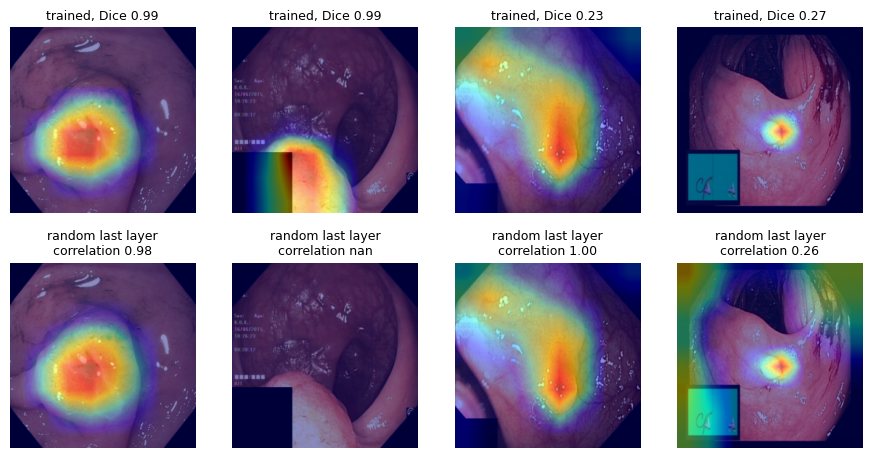

similarity trained vs random-last-layer maps (correlation, 1 = identical): 0.98 nan 1.00 0.26


In [3]:
# Same Grad-CAM as notebook 03 (on layer4).
def gradcam(model, x):
    acts = {}
    hook = model.layer4.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    out = model(x); hook.remove()
    target = (out * (out > 0).float()).sum()
    # Safety: for a random layer maybe no pixel is called polyp.
    if target.item() == 0:                               # nothing called polyp: use all logits
        target = out.sum()
    g = torch.autograd.grad(target, acts["a"])[0]
    cam = F.relu((g.mean((2, 3), keepdim=True) * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[:, 0]
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).detach().cpu().numpy()

trained = models[("pretrained", 0)]
# B5 sanity check (Adebayo et al. 2018): a copy of the trained model...
random_last = copy.deepcopy(trained)
torch.manual_seed(1)
# ... whose LAST layer gets new random weights. A good heat map must then change.
random_last.final[-1].reset_parameters()                # new random weights in the last layer only

d = np.array([mean_scores([p > 0.5], [y])["dice"] for p, y in zip(ens["pretrained"], Y)])
show = list(np.argsort(-d)[:2]) + list(np.argsort(d)[:2])        # 2 best, 2 worst
x = normalise(to_tensor(X[show]).to(device))
cams_t, cams_r = gradcam(trained, x), gradcam(random_last, x)
# Correlation of the two maps: 1 = identical (bad), near 0 = changed (good).
same = [float(np.corrcoef(a.ravel(), b.ravel())[0, 1]) for a, b in zip(cams_t, cams_r)]

fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for k, i in enumerate(show):
    for r, (c, t) in enumerate([(cams_t[k], "trained"), (cams_r[k], "random last layer")]):
        axes[r, k].imshow(X[i]); axes[r, k].imshow(c, cmap="jet", alpha=0.45)
        axes[r, k].set_title(f"{t}" + (f"\ncorrelation {same[k]:.2f}" if r == 1 else f", Dice {d[i]:.2f}"), fontsize=9)
        axes[r, k].axis("off")
fig.savefig(R / "B5_sanity.png", dpi=150, bbox_inches="tight"); plt.show()
print("similarity trained vs random-last-layer maps (correlation, 1 = identical):",
      " ".join(f"{s:.2f}" for s in same))

---
## C3 · Calibration: when the U-Net says 70 % polyp, is it polyp 7 times in 10?
Every test pixel (120 × 256 × 256), grouped by its predicted probability (mean of the 3 seeds),
compared with how often it really was polyp. Calibration error (ECE): 0 = honest probabilities.

scratch    calibration error 0.023
pretrained calibration error 0.063


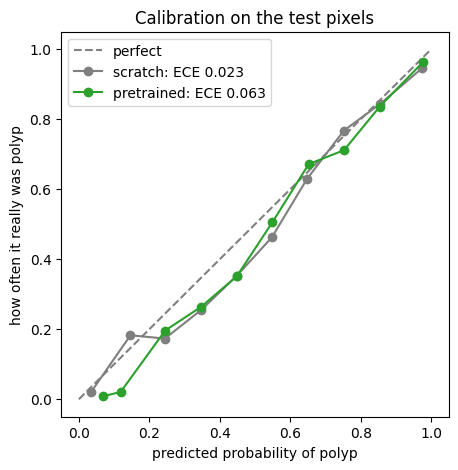

106

In [4]:
# C3 calibration: when the model says 70 %, is it polyp 70 % of the time?
def calibration(p, truth, bins=10):
    p, truth = p.ravel(), truth.ravel().astype(float)
    # Put every pixel into one of 10 bins by its predicted probability.
    idx = np.clip((p * bins).astype(int), 0, bins - 1)
    # Per bin: the mean predicted probability ...
    mean_p = np.array([p[idx == b].mean() if (idx == b).any() else np.nan for b in range(bins)])
    # ... and the fraction of pixels that really are polyp.
    frac = np.array([truth[idx == b].mean() if (idx == b).any() else np.nan for b in range(bins)])
    n = np.array([(idx == b).sum() for b in range(bins)])
    # ECE = weighted mean gap between the two (0 = perfectly honest).
    ece = float(np.nansum(n * np.abs(mean_p - frac)) / len(p))
    return mean_p, frac, ece

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
lines = ["| U-Net (mean of 3 seeds) | calibration error (ECE) |", "|---|---|"]
for name, colour in (("scratch", "tab:gray"), ("pretrained", "tab:green")):
    mean_p, frac, ece = calibration(ens[name], Y)
    ax.plot(mean_p, frac, "o-", color=colour, label=f"{name}: ECE {ece:.3f}")
    lines.append(f"| {name} | {ece:.3f} |")
    print(f"{name:10s} calibration error {ece:.3f}")
ax.set_xlabel("predicted probability of polyp"); ax.set_ylabel("how often it really was polyp")
ax.set_title("Calibration on the test pixels"); ax.legend()
fig.savefig(R / "C3_calibration.png", dpi=150, bbox_inches="tight"); plt.show()
(R / "C3_calibration.md").write_text("\n".join(lines), encoding="utf-8")

---
## C5 · `requirements.txt` with the exact versions used on Colab

In [5]:
# Write the exact package versions of this Colab run to requirements.txt (reproducibility).
import scipy, matplotlib, PIL, torchvision
req = (f"numpy=={np.__version__}\nscipy=={scipy.__version__}\nmatplotlib=={matplotlib.__version__}\n"
       f"Pillow=={PIL.__version__}\ntorch=={torch.__version__.split('+')[0]}\n"
       f"torchvision=={torchvision.__version__.split('+')[0]}\njupyter\n")
Path("requirements.txt").write_text(req); print(req)

import zipfile
with zipfile.ZipFile("results_04.zip", "w") as z:
    for f in ("B5_sanity.png", "C3_calibration.png", "C3_calibration.md"):
        z.write(R / f)
    z.write("requirements.txt")
try:
    from google.colab import files; files.download("results_04.zip")
except ImportError:
    print("results_04.zip written")

numpy==2.4.6
scipy==1.16.3
matplotlib==3.10.0
Pillow==11.3.0
torch==2.14.1
torchvision==0.29.1
jupyter



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>